# Conversation engagement and verified OP deltas

**How do observed volume, depth, and OP participation differ between branches that receive a delta and those that do not?** Use the existing branch-level training dataset. Follow each eligible opening for seven days from its timestamp, and use the same window for engagement and the first verified OP delta. Counts can include the award event and replies that followed it. This is a retrospective association analysis.

The [analysis script](branch_engagement_analysis/analyze_branch_engagement.py) reuses the verified-award window rules and reconstructs parent–child paths from training metadata. Uncertain paths and award times affect eligibility as recorded below. A zero descendant count in this cohort means no descendant was observed within the seven-day window.

| Feature | Calculation |
| --- | --- |
| OP replies | OP-authored descendants at any depth |
| Direct replies | Descendants immediately under the opening |
| Total descendants | All observed descendants within the window |
| Maximum depth | Deepest descendant, with the opening at depth 0 |
| Mean depth | Mean depth across descendants |
| Maximum OP depth | Deepest OP-authored descendant |

Depth summaries are zero when there are no relevant replies. Primary counts include award comments and bot confirmations. The award-omitted analysis removes those messages, connects each retained descendant to its closest retained ancestor, and recalculates direct replies and depths.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/branch-engagement-analysis"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    raise FileNotFoundError("Run analyze_branch_engagement.py to create the analysis artifacts.")
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
run = report_path.parent
report = json.loads(report_path.read_text())
assert report["split"] == "train" and report["followup_days"] == 7
print(f"{report['branches']:,} eligible branches, {report['discussions']:,} OP discussions, and {report['deltas']:,} verified deltas.")
print(f"Feature table: {run / 'engagement_features.parquet'}")
display(pd.Series(report["eligibility"], name="Branches").to_frame())
print(f"In-window comments excluded for an out-of-window ancestor: {report['window_descendants_without_in_window_parent']:,}.")

213,563 eligible branches, 18,044 OP discussions, and 6,131 verified deltas.
Feature table: /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/branch-engagement-analysis/20261121T201206041502Z/engagement_features.parquet


,Branches
Eligible,213563
Outside valid challenger/bot-period/timestamp cohort,2849
Insufficient seven-day follow-up,2186
Uncertain award attribution during follow-up,1014
Incomplete parent path during follow-up,466
Award and confirmation cross a window boundary,48


In-window comments excluded for an out-of-window ancestor: 0.


## A. Engagement distributions

Each curve shows the share of branches whose feature value exceeds the horizontal coordinate. The height at zero therefore shows the share with a nonzero value. Full-cohort Spearman correlations can be high when several features share the same large set of zero-reply branches.

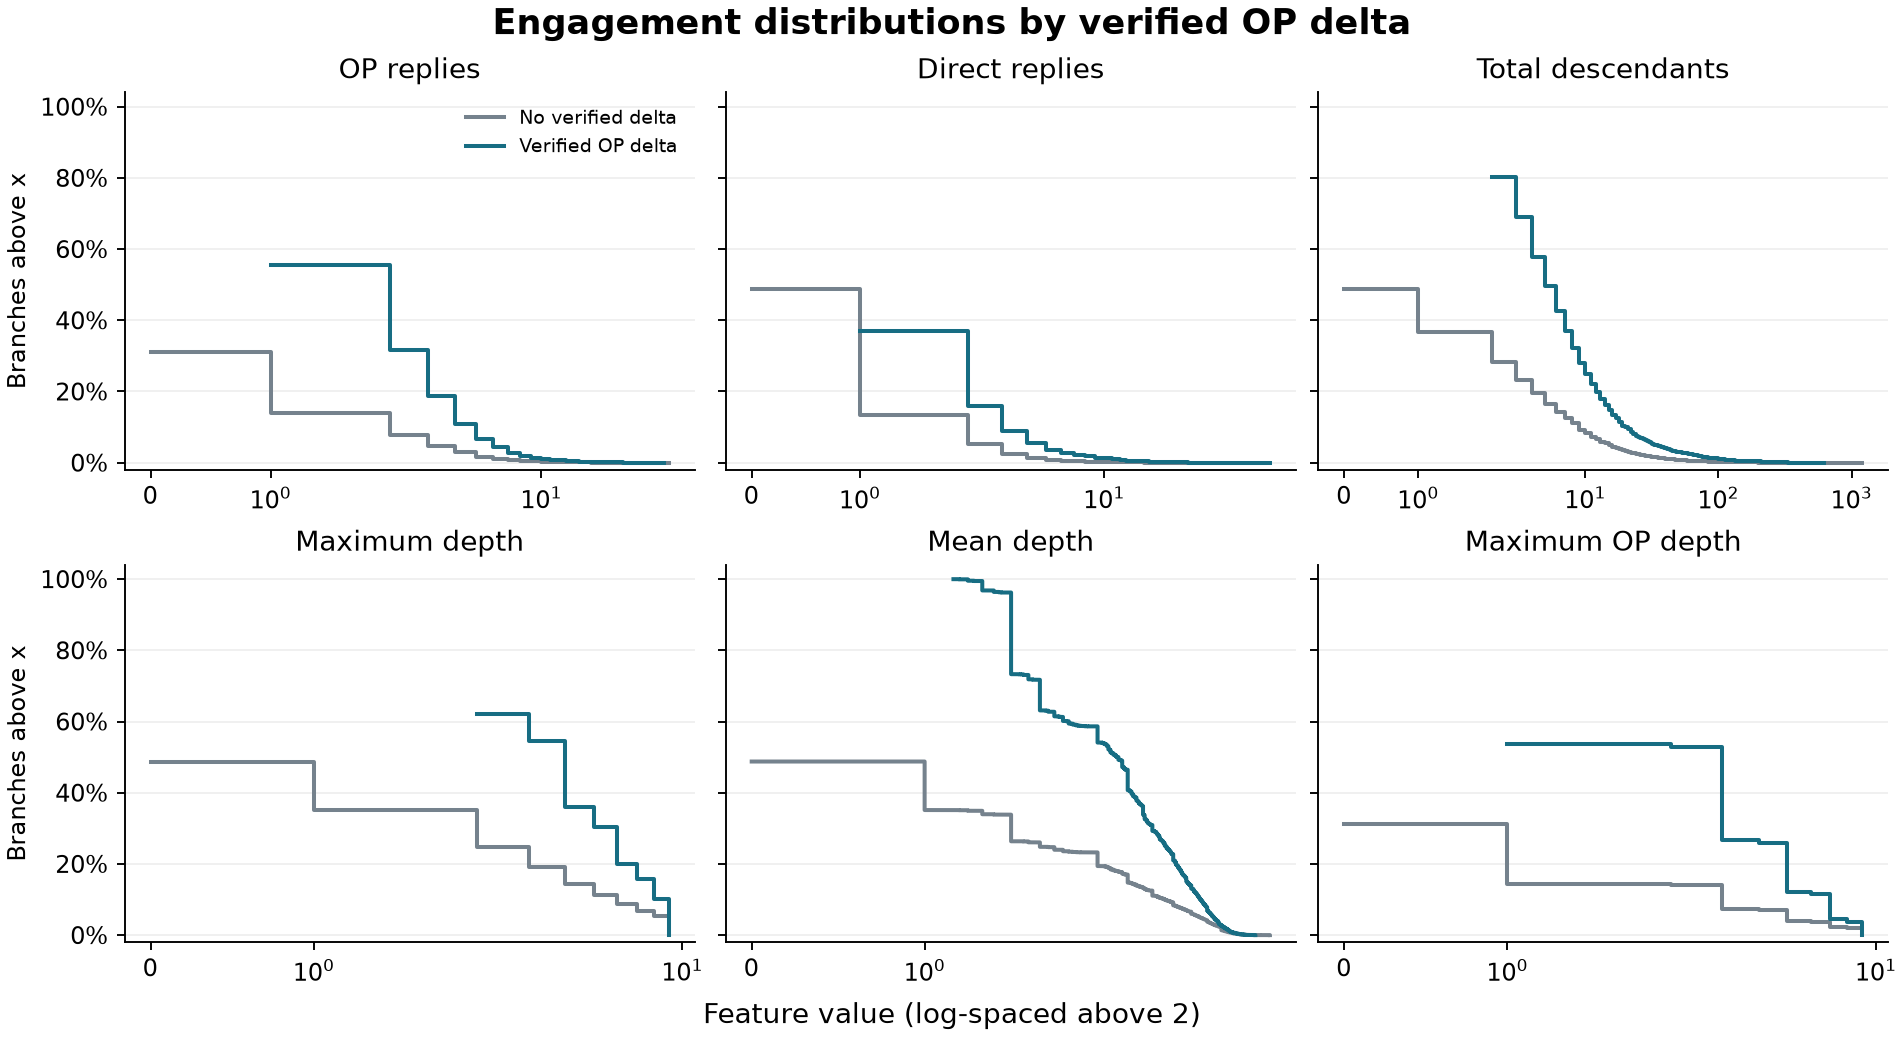

branches   mean  median  Zero (%)    p90     p99
verified_op_delta feature                                                         
0                 op_replies        207432   0.66    0.00     68.85   2.00    7.00
                  direct_replies    207432   0.75    0.00     51.24   2.00    5.00
                  total_replies     207432   3.62    0.00     51.24   9.00   44.00
                  max_depth         207432   1.74    0.00     51.24   6.00    9.00
                  mean_depth        207432   1.08    0.00     51.24   3.29    5.18
                  max_op_depth      207432   0.86    0.00     68.85   3.00    9.00
1                 op_replies          6131   2.39    2.00      0.00   5.00   11.00
                  direct_replies      6131   1.86    1.00      0.00   3.00   11.00
                  total_replies       6131  11.02    5.00      0.00  20.00  105.70
                  max_depth           6131   4.29    4.00      0.00   9.00    9.00
                  mean_depth          6131   2.55    2.33      0.00   4.28    5.33
                  max_op_depth        6131   2.91    3.00      0.00   7.00    9.00

,op_replies,direct_replies,total_replies,max_depth,mean_depth,max_op_depth
op_replies,1.000,0.661,0.726,0.731,0.734,0.998
direct_replies,0.661,1.000,0.944,0.922,0.912,0.660
total_replies,0.726,0.944,1.000,0.993,0.990,0.727
max_depth,0.731,0.922,0.993,1.000,0.999,0.733
mean_depth,0.734,0.912,0.990,0.999,1.000,0.736
max_op_depth,0.998,0.660,0.727,0.733,0.736,1.000


In [2]:
display(Image(filename=str(run / "engagement_distributions.png")))
distribution = pd.read_csv(run / "engagement_distributions.csv")
distribution["zero_share"] *= 100
display(distribution.rename(columns={"zero_share": "Zero (%)"}).set_index(
    ["verified_op_delta", "feature"]
).round(2))
correlation = pd.read_csv(run / "spearman_correlations.csv", index_col=0)
display(correlation.round(3))

## B. Delta rate by volume and depth

The denominator is eligible branches in each bin. The rates cover the common seven-day follow-up. Intervals use 1,000 bootstrap samples of whole OP discussions. For empty cells and observed rates of zero or one, the table leaves the percentile interval blank because resampling cannot reveal events absent from the cell. The plot shows total descendants and maximum depth. The table includes all six features.

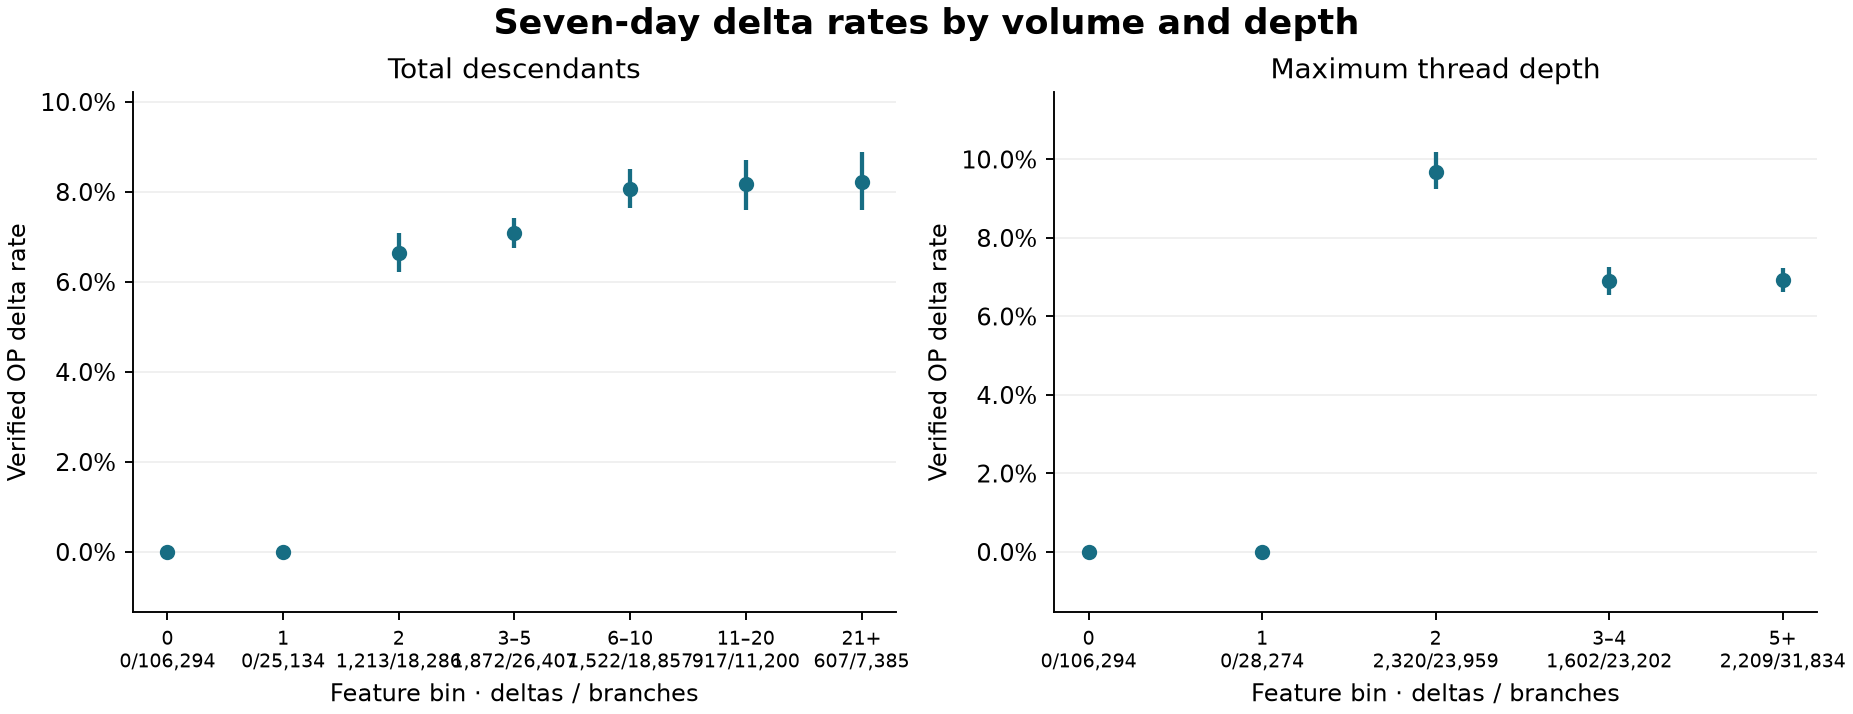

branches  events  discussions   rate  ci_low  ci_high
feature        group                                                       
total_replies  0        106294       0        16001   0.00     NaN      NaN
               1         25134       0        11643   0.00     NaN      NaN
               2         18286    1213        10295   6.63    6.21     7.08
               3–5       26407    1872        12718   7.09    6.75     7.43
               6–10      18857    1522        10511   8.07    7.65     8.50
               11–20     11200     917         7215   8.19    7.60     8.72
               21+        7385     607         4236   8.22    7.59     8.88
max_depth      0        106294       0        16001   0.00     NaN      NaN
               1         28274       0        12292   0.00     NaN      NaN
               2         23959    2320        11887   9.68    9.24    10.18
               3–4       23202    1602        11841   6.90    6.54     7.25
               5+        31834    2209        11921   6.94    6.61     7.24
op_replies     0        142814       0        16580   0.00     NaN      NaN
               1         38494    2730        13788   7.09    6.77     7.44
               2         14336    1455         8574  10.15    9.62    10.67
               3–5       14067    1542         7563  10.96   10.40    11.54
               6–10       3246     339         2353  10.44    9.33    11.62
               11–20       540      55          483  10.19    7.62    12.83
               21+          66      10           63  15.15    7.01    23.53
direct_replies 0        106294       0        16001   0.00     NaN      NaN
               1         77044    3860        16919   5.01    4.83     5.21
               2         18417    1298        10074   7.05    6.65     7.45
               3–5        9788     748         5865   7.64    7.09     8.22
               6–10       1566     152         1216   9.71    8.29    11.32
               11–20       388      62          347  15.98   12.39    19.57
               21+          66      11           64  16.67    8.06    26.32
mean_depth     0        106294       0        16001   0.00     NaN      NaN
               >0–1      28274       0        12292   0.00     NaN      NaN
               >1–2      35448    2815        14204   7.94    7.59     8.31
               >2–4      30368    2516        12918   8.29    7.92     8.62
               >4        13179     800         6806   6.07    5.66     6.51
max_op_depth   0        142814       0        16580   0.00     NaN      NaN
               >0–1      37512    2835        13637   7.56    7.23     7.92
               >1–2       1102      63         1024   5.72    4.35     7.22
               >2–4      15874    1650         9028  10.39    9.90    10.90
               >4        16261    1583         7532   9.73    9.23    10.26

In [3]:
display(Image(filename=str(run / "delta_rate_by_volume_and_depth.png")))
marginal = pd.read_csv(run / "marginal_rates.csv", dtype={"group": str})
fields = ["rate", "ci_low", "ci_high"]
marginal[fields] *= 100
display(marginal.set_index(["feature", "group"]).round(2))

## C. OP participation and depth at comparable volumes

In the left panel, count OP replies and total descendants after omitting verified award comments and their linked bot confirmations. Keep the delta outcome unchanged. This reduces the direct overlap between the event definition and the OP-participation feature. The right panel uses observed maximum depth and total volume, with depth 3+ compared with depth 0–2. Bins can still contain different exact reply counts, and some shallow/deep combinations are structurally impossible. The table also includes the OP comparison with all observed comments.

The primary descriptive logistic regression uses the award-omitted counts, categorical volume, any OP reply, and `log2(1 + maximum depth)` measured on the retained tree. It reports odds ratios with OP-discussion-clustered confidence intervals. A one-unit increase in transformed depth doubles one plus the maximum depth. The model adjusts for reply volume. Subsequent comments and unmeasured properties of the opening may still influence the associations.

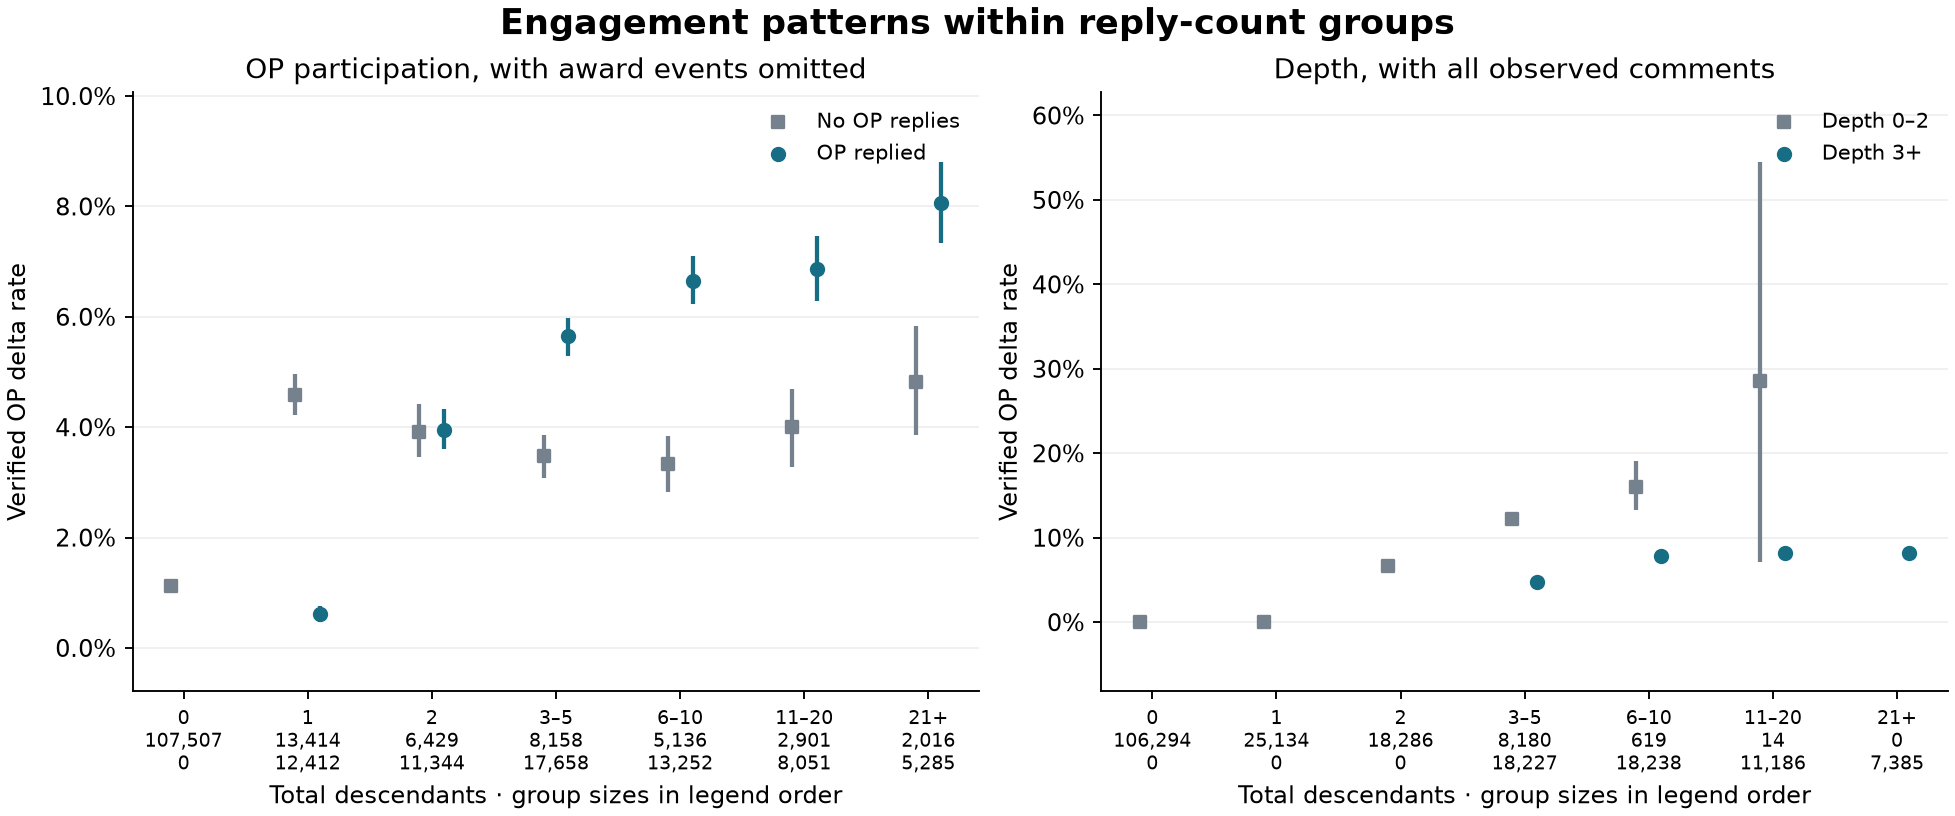

branches  events  discussions   rate  ci_low  ci_high
comparison                     volume indicator                                                       
op_participation               0      0            106294       0        16001   0.00     NaN      NaN
                                      1                 0       0            0    NaN     NaN      NaN
                               1      0             12799       0         6952   0.00     NaN      NaN
                                      1             12335       0         7081   0.00     NaN      NaN
                               2      0              6177       0         4330   0.00     NaN      NaN
                                      1             12109    1213         7613  10.02    9.41    10.68
                               3–5    0              7875       0         5060   0.00     NaN      NaN
                                      1             18532    1872        10122  10.10    9.61    10.59
                               6–10   0              4965       0         3426   0.00     NaN      NaN
                                      1             13892    1522         8469  10.96   10.40    11.55
                               11–20  0              2785       0         2077   0.00     NaN      NaN
                                      1              8415     917         5902  10.90   10.14    11.61
                               21+    0              1919       0         1277   0.00     NaN      NaN
                                      1              5466     607         3558  11.11   10.27    11.99
op_participation_without_award 0      0            107507    1213        16113   1.13    1.05     1.21
                                      1                 0       0            0    NaN     NaN      NaN
                               1      0             13414     615         7329   4.58    4.23     4.97
                                      1             12412      77         7109   0.62    0.47     0.76
                               2      0              6429     252         4511   3.92    3.46     4.43
                                      1             11344     448         7266   3.95    3.60     4.32
                               3–5    0              8158     283         5256   3.47    3.08     3.86
                                      1             17658     998         9756   5.65    5.28     5.99
                               6–10   0              5136     171         3550   3.33    2.82     3.83
                                      1             13252     882         8144   6.66    6.23     7.10
                               11–20  0              2901     116         2163   4.00    3.27     4.69
                                      1              8051     553         5666   6.87    6.29     7.46
                               21+    0              2016      97         1336   4.81    3.86     5.83
                                      1              5285     426         3455   8.06    7.33     8.81
deep_branch                    0      0            106294       0        16001   0.00     NaN      NaN
                                      1                 0       0            0    NaN     NaN      NaN
                               1      0             25134       0        11643   0.00     NaN      NaN
                                      1                 0       0            0    NaN     NaN      NaN
                               2      0             18286    1213        10295   6.63    6.21     7.08
                                      1                 0       0            0    NaN     NaN      NaN
                               3–5    0              8180    1004         6104  12.27   11.54    13.04
                                      1             18227     868        10339   4.76    4.44     5.06
                               6–10   0               619      99          593  15.99   13.23    19.06
                                

,odds_ratio,ci_low,ci_high
term,,,
intercept,0.0114,0.0107,0.0122
volume_1,4.4620,3.8704,5.1440
volume_2,9.0138,7.5949,10.6978
volume_3–5,15.7240,12.9439,19.1012
volume_6–10,28.0230,21.8737,35.9011
volume_11–20,38.8324,29.0065,51.9867
volume_21+,54.8195,39.9138,75.2917
op_participated,1.1351,1.0650,1.2097
log2_max_depth,0.5078,0.4645,0.5552


Delta-winning branches with zero OP replies in observed counts: 0.
Delta-winning branches with zero OP replies after event omission: 2,747.


In [4]:
display(Image(filename=str(run / "op_participation_and_depth_by_volume.png")))
stratified = pd.read_csv(run / "stratified_rates.csv", dtype={"volume": str, "indicator": str})
stratified[fields] *= 100
display(stratified.set_index(["comparison", "volume", "indicator"]).round(2))

adjusted = pd.read_csv(run / "adjusted_associations.csv")
display(adjusted.set_index("term")[["odds_ratio", "ci_low", "ci_high"]].round(4))

print(f"Delta-winning branches with zero OP replies in observed counts: {report['positive_branches_with_no_op_reply']:,}.")
print(f"Delta-winning branches with zero OP replies after event omission: {report['positive_branches_with_no_op_reply_when_omitting_awards']:,}.")

## Interpretation

Winning branches had more observed replies and deeper exchanges, with volume and depth strongly correlated. Every delta-winning branch included an OP reply in the full-window counts. Almost half had no remaining OP reply after omitting the verified award event and confirmation. In the adjusted analysis, the association for any OP reply versus none was small. The depth results are sensitive to counting rules and adjustment. The depth audit below compares the original and contracted trees on the same branches.

A delta can change what happens later in the same branch. Omitting award messages preserves other descendants, including replies posted after the award. The estimates describe retrospective associations, and the temporal ordering leaves causal effects and prospective predictive value unresolved.

## Sensitivity to counting award events

Compare the same branches and delta outcomes under both counting rules. When omitting award events, recompute the volume and depth bins from remaining comments. A branch can move to another bin. Depths are recalculated after connecting each retained descendant to its nearest retained ancestor. The chart labels show deltas and branch counts, with 95% discussion-bootstrap intervals where supported.

The [audit script](branch_engagement_analysis/audit_branch_engagement.py) uses the archived training feature table.

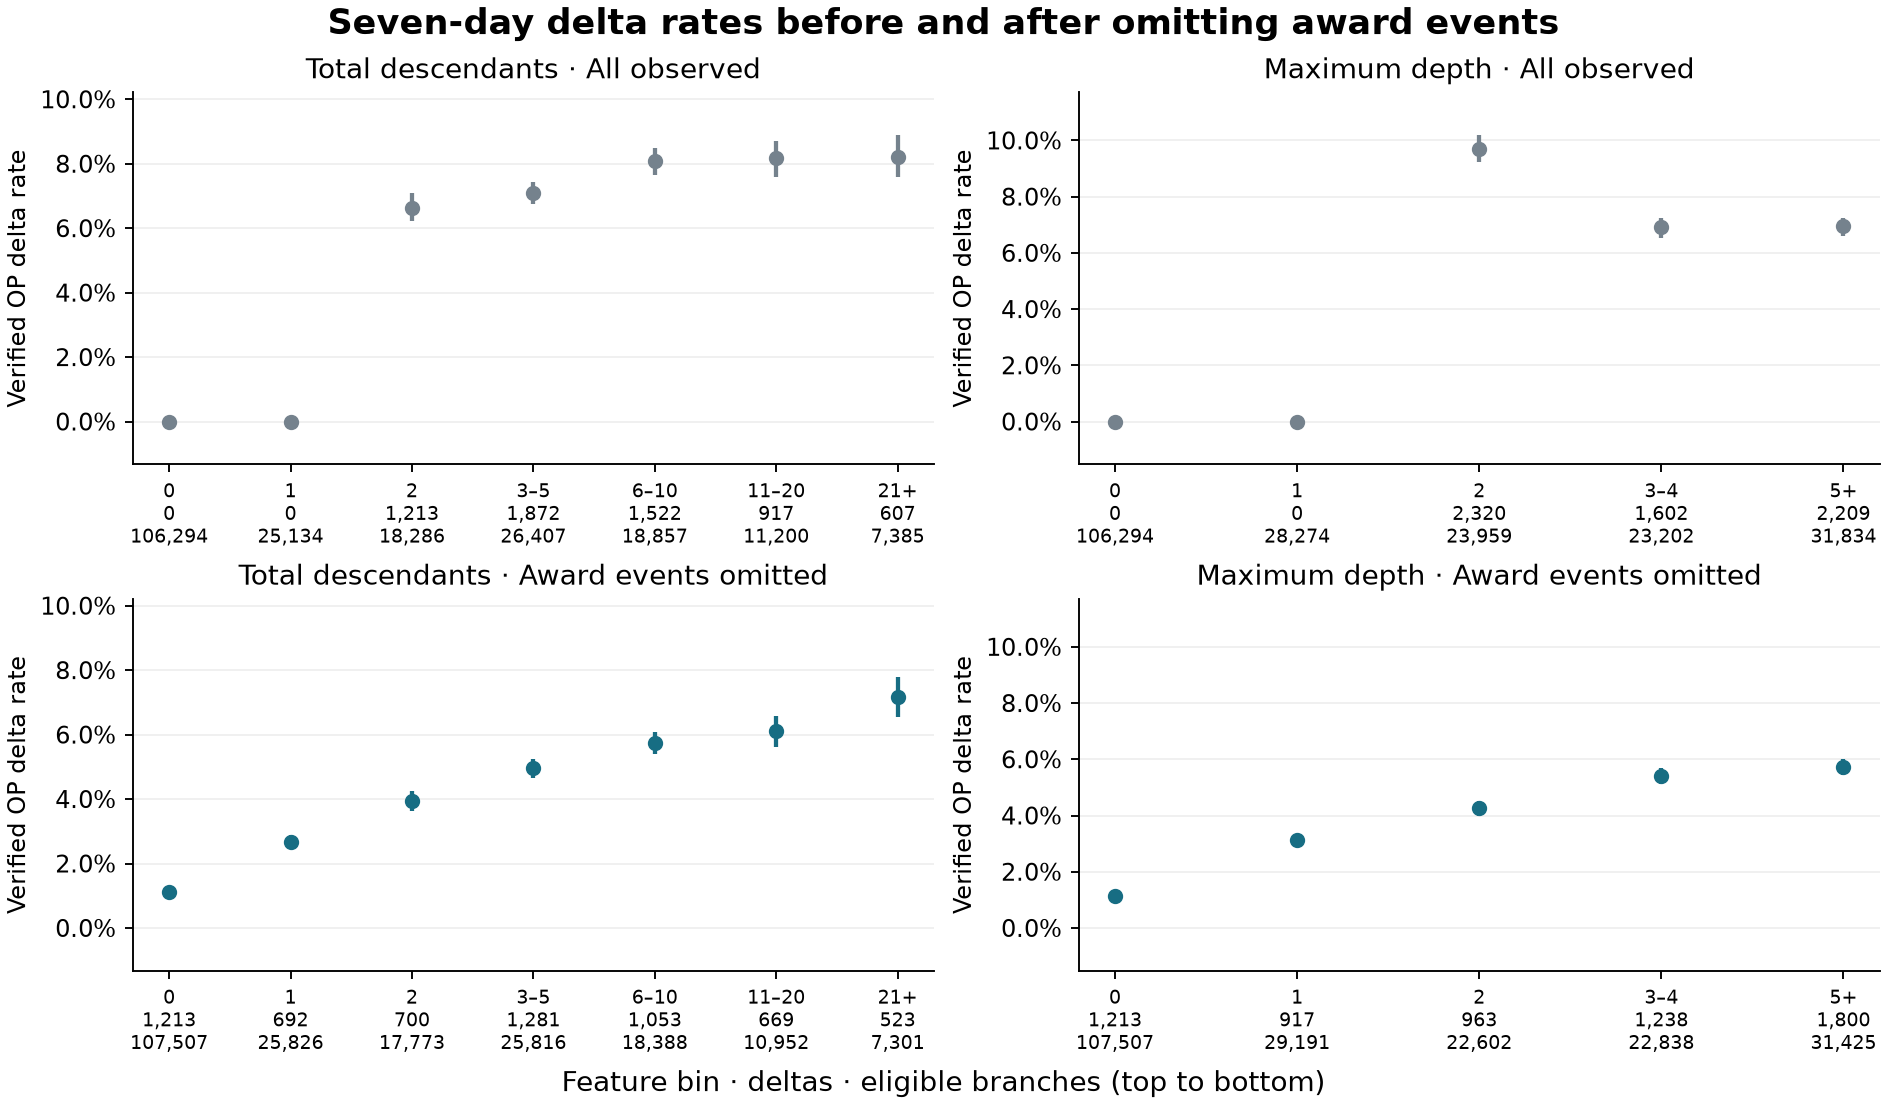

branches  events  discussions  rate  ci_low  ci_high
feature           counting_rule        group                                                      
Total descendants All observed         0        106294       0        16001  0.00     NaN      NaN
                                       1         25134       0        11643  0.00     NaN      NaN
                                       2         18286    1213        10295  6.63    6.21     7.08
                                       3–5       26407    1872        12718  7.09    6.75     7.43
                                       6–10      18857    1522        10511  8.07    7.65     8.50
                                       11–20     11200     917         7215  8.19    7.60     8.72
                                       21+        7385     607         4236  8.22    7.59     8.88
Maximum depth     All observed         0        106294       0        16001  0.00     NaN      NaN
                                       1         28274       0        12292  0.00     NaN      NaN
                                       2         23959    2320        11887  9.68    9.24    10.18
                                       3–4       23202    1602        11841  6.90    6.54     7.25
                                       5+        31834    2209        11921  6.94    6.61     7.24
Total descendants Award events omitted 0        107507    1213        16113  1.13    1.05     1.21
                                       1         25826     692        11858  2.68    2.48     2.88
                                       2         17773     700        10140  3.94    3.64     4.24
                                       3–5       25816    1281        12534  4.96    4.66     5.24
                                       6–10      18388    1053        10307  5.73    5.39     6.09
                                       11–20     10952     669         7061  6.11    5.61     6.57
                                       21+        7301     523         4186  7.16    6.55     7.80
Maximum depth     Award events omitted 0        107507    1213        16113  1.13    1.05     1.21
                                       1         29191     917        12542  3.14    2.92     3.35
                                       2         22602     963        11521  4.26    4.00     4.53
                                       3–4       22838    1238        11729  5.42    5.12     5.71
                                       5+        31425    1800        11789  5.73    5.45     6.02

branches  events   rate  ci_low  ci_high
counting_rule        volume depth_group                                          
All observed         3–5    Depth 0–2        8180    1004  12.27   11.54    13.04
                            Depth 3+        18227     868   4.76    4.44     5.06
                     6–10   Depth 0–2         619      99  15.99   13.23    19.06
                            Depth 3+        18238    1423   7.80    7.38     8.23
                     11–20  Depth 0–2          14       4  28.57    7.14    54.55
                            Depth 3+        11186     913   8.16    7.56     8.70
Award events omitted 3–5    Depth 0–2        7606     430   5.65    5.12     6.21
                            Depth 3+        18210     851   4.67    4.35     4.97
                     6–10   Depth 0–2         570      50   8.77    6.53    11.35
                            Depth 3+        17818    1003   5.63    5.28     5.98
                     11–20  Depth 0–2          18       8  44.44   22.22    66.67
                            Depth 3+        10934     661   6.05    5.55     6.50

In [5]:
audit_base = RUNS / "sensitivity"
audit_files = sorted(audit_base.glob("*/results.json"))
audit_path = next(
    path for path in reversed(audit_files)
    if json.loads(path.read_text())["source_run"] == run.name
)
audit = audit_path.parent
audit_report = json.loads(audit_path.read_text())
assert audit_report["branches"] == report["branches"] and audit_report["events"] == report["deltas"]
display(Image(filename=str(audit / "award_omission_volume_depth.png")))
adjusted_bins = pd.read_csv(audit / "volume_depth_rates.csv", dtype={"group": str})
rate_fields = ["rate", "ci_low", "ci_high"]
adjusted_bins[rate_fields] *= 100
display(adjusted_bins.set_index(["feature", "counting_rule", "group"]).round(2))

strata_depth = pd.read_csv(audit / "depth_by_volume.csv", dtype={"volume": str, "indicator": str})
strata_depth[rate_fields] *= 100
supported = strata_depth.groupby(["counting_rule", "volume"])["branches"].transform("min").gt(0)
display(strata_depth.loc[supported].assign(
    depth_group=lambda data: data["indicator"].map({"0": "Depth 0–2", "1": "Depth 3+"}),
).set_index(["counting_rule", "volume", "depth_group"])[["branches", "events", *rate_fields]].round(2))

## Audit of retained descendant paths

The original award-omitted calculation removed award comments and confirmations from counts while retaining the original depth of each remaining node. Its count and depth therefore referred to different trees. This table traces the branches previously flagged for having depth 3+ with one or two retained comments.

The corrected tree skips omitted ancestors. Each retained comment still connects to the opening through its closest retained ancestor. Comments with no observed in-window path were already excluded during reconstruction. The regression table retains the original-position fit as a diagnostic, alongside the new contracted-depth fit.

In [6]:
flagged = pd.read_csv(audit / "flagged_branch_depth_audit.csv")
assert len(flagged) == audit_report["flagged_branches"]
assert flagged["max_depth_without_award"].le(flagged["total_replies_without_award"]).all()
display(flagged.groupby("total_replies_without_award").agg(
    flagged_branches=("branch_id", "size"),
    deltas=("verified_op_delta", "sum"),
    largest_original_position=("max_depth_original_positions", "max"),
    largest_retained_depth=("max_depth_without_award", "max"),
))
print(f"Branches with maximum retained depth greater than retained count: {audit_report['remaining_impossible_depths']}")
print(f"Branch-level audit: {audit / 'flagged_branch_depth_audit.csv'}")

,flagged_branches,deltas,largest_original_position,largest_retained_depth
total_replies_without_award,,,,
1,42,42,3,1
2,156,156,4,2


Branches with maximum retained depth greater than retained count: 0
Branch-level audit: /Users/paolacalle/Desktop/NYU/semesters/fall-2026/ml-viz/ml-visualization-project/ml-visualization-project/project/data/processed/branch-engagement-analysis/sensitivity/20261121T201219390203Z/flagged_branch_depth_audit.csv


## Correlations among nonempty branches

Recalculate the feature correlations in branches with at least one and at least two observed descendants. Membership in each subset uses the count under that row's counting rule. This helps show how much the shared zeros inflate the original correlations.

In [7]:
correlation_audit = pd.read_csv(audit / "engagement_spearman_sensitivity.csv")
selected_pairs = {
    ("max_depth", "mean_depth"): "Max vs. mean depth",
    ("total_replies", "max_depth"): "Total replies vs. max depth",
    ("op_replies", "max_op_depth"): "OP replies vs. max OP depth",
    ("direct_replies", "total_replies"): "Direct vs. total replies",
}
correlation_audit["features"] = [
    selected_pairs.get((a, b)) for a, b in zip(correlation_audit["feature_1"], correlation_audit["feature_2"])
]
display(correlation_audit.dropna(subset="features").pivot(
    index=["counting_rule", "subset", "branches"], columns="features", values="spearman",
).round(3))

features                                                Direct vs. total replies  Max vs. mean depth  OP replies vs. max OP depth  Total replies vs. max depth
counting_rule        subset                   branches                                                                                                        
All observed         All eligible branches    213563                       0.944               0.999                        0.998                        0.993
                     At least one descendant  107269                       0.543               0.990                        0.991                        0.948
                     At least two descendants 82135                        0.469               0.977                        0.985                        0.900
Award events omitted All eligible branches    213563                       0.946               0.999                        0.998                        0.993
                     At least one descendant  106056                       0.544               0.990                        0.991                        0.949
                     At least two descendants 80230                        0.464               0.978                        0.986                        0.900

## Regression audit

The main audit uses award-omitted counts. The primary model includes volume, any OP reply, and maximum retained-tree depth. Use volume-only and simpler nested fits for comparison. Substitute mean depth in a sensitivity fit. Maximum and mean depth have high rank correlation, so the model never includes both. The models use the same cohort and volume bins. Both depth terms are `log2(1 + depth)`. A one-unit change doubles one plus depth. The OP indicator compares any OP reply versus none.

Volume-bin odds ratios compare each bin with the zero-descendant reference while holding any additional covariates fixed. Some combinations are impossible, such as zero descendants with positive depth. Once depth is included, interpret these bin coefficients as model parameters, with the binned rates supplying the observed comparisons. The variance inflation factor (VIF) is a diagnostic for correlated predictors.

To compare depth definitions on the same branches, also fit volume and depth in a common sample with at least three award-omitted descendants. This gives both outcomes in every included volume bin under both counting rules. The reference is 3–5 descendants under the corresponding rule. The former award-omitted calculation that preserved original positions is included as a diagnostic. Every full-count delta contains an OP reply, so the common-sample fits omit the OP indicator. Intervals account for clustering by OP discussion.

In [8]:
audit_models = pd.read_csv(audit / "regression_audit.csv")
focus = ["op_participated", "log2_max_depth", "log2_mean_depth"]
detail = audit_models.set_index(["cohort", "specification", "term"])
view = ["odds_ratio", "ci_low", "ci_high", "vif", "volume_reference"]
display(detail.loc[detail.index.get_level_values("term").isin(focus), view].round(4))
all_eligible = audit_models.loc[audit_models["cohort"].eq("All eligible · award events omitted")]
volume_terms = all_eligible.loc[all_eligible["term"].str.startswith("volume_")]
display(volume_terms.pivot(index="term", columns="specification", values="odds_ratio").round(3))
print(f"Common-sample regressions use {audit_report['common_sample_branches']:,} branches.")

odds_ratio  ci_low  ci_high      vif volume_reference
cohort                                                    specification            term                                                                  
All eligible · award events omitted                       Volume + OP              op_participated      1.1053  1.0364   1.1787   1.9787                0
                                                          Volume + max depth       log2_max_depth       0.5134  0.4693   0.5617  31.0036                0
                                                          Volume + OP + max depth  op_participated      1.1351  1.0650   1.2097   1.9839                0
                                                                                   log2_max_depth       0.5078  0.4645   0.5552  31.0845                0
                                                          Volume + OP + mean depth op_participated      1.1608  1.0893   1.2369   1.9890                0
                                                                                   log2_mean_depth      0.3375  0.2993   0.3805  30.9203                0
Common sample · All observed                              Volume + max depth       log2_max_depth       0.5673  0.5190   0.6200   2.6902              3–5
                                                          Volume + mean depth      log2_mean_depth      0.5396  0.4821   0.6039   2.1427              3–5
Common sample · Award events omitted                      Volume + max depth       log2_max_depth       0.5264  0.4797   0.5777   2.7155              3–5
                                                          Volume + mean depth      log2_mean_depth      0.3563  0.3152   0.4028   2.1599              3–5
Common sample · Award events omitted · original positions Volume + max depth       log2_max_depth       1.3375  1.2037   1.4861   2.7024              3–5
                                                          Volume + mean depth      log2_mean_depth      1.3418  1.1821   1.5231   2.1557              3–5

specification,Volume + OP,Volume + OP + max depth,Volume + OP + mean depth,Volume + max depth,Volume only
term,,,,,
volume_1,2.297,4.462,6.637,4.699,2.413
volume_11–20,5.292,38.832,55.265,41.291,5.701
volume_2,3.367,9.014,12.877,9.622,3.593
volume_21+,6.284,54.820,79.136,58.052,6.762
volume_3–5,4.268,15.724,22.322,16.803,4.575
volume_6–10,4.948,28.023,40.171,29.873,5.323


Common-sample regressions use 62,457 branches.


## What the depth correction changed

The prior calculation reproduced the positive maximum-depth odds ratio of 1.34 with the same retained comment counts. Recalculating depth on the connected retained tree moved that estimate to 0.53 on the same 62,457 branches. The comparable all-comments estimate was 0.57. The old direction reversal disappeared when the depth and reply count came from the same tree. Some retained descendants of awards had been counted at positions made artificially deep by ancestors that were omitted from volume.

The primary model uses a single depth variable. After adjusting for retained volume and maximum depth, the odds ratio for any OP reply versus none is about 1.14. This is a modest conditional association. Some measured activity still occurred after the award, and volume and depth remain related, so the estimates describe the observed seven-day conversations.